<a href="https://colab.research.google.com/github/venkatasai-eng/Computer-Vision/blob/main/Exp_38.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install -q opencv-python

Saving human faces.jpg to human faces (2).jpg


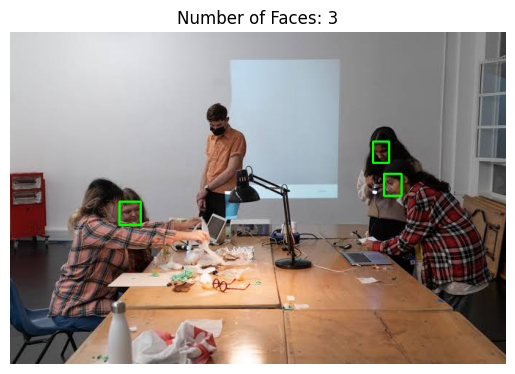

Total faces detected: 3


In [7]:
import cv2
import matplotlib.pyplot as plt
import urllib.request
from google.colab import files

url = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
model = "face_detection_yunet_2023mar.onnx"
urllib.request.urlretrieve(url, model)

uploaded = files.upload()
path = next(iter(uploaded))

img = cv2.imread(path)

if img is None:
    raise ValueError("Unable to read image. Upload a JPG or PNG image.")

h, w = img.shape[:2]

detector = cv2.FaceDetectorYN.create(
    model, "", (w, h), 0.8, 0.3, 5000
)

_, faces = detector.detect(img)

count = 0 if faces is None else len(faces)

if faces is not None:
    for face in faces:
        x, y, fw, fh = map(int, face[:4])
        cv2.rectangle(img, (x, y), (x + fw, y + fh), (0, 255, 0), 2)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title(f"Number of Faces: {count}")
plt.axis("off")
plt.show()

print("Total faces detected:", count)